In [24]:
import pandas as pd
df = pd.read_csv("Churn_Modelling.csv")
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,NaN,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,NaN,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          9998 non-null   object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


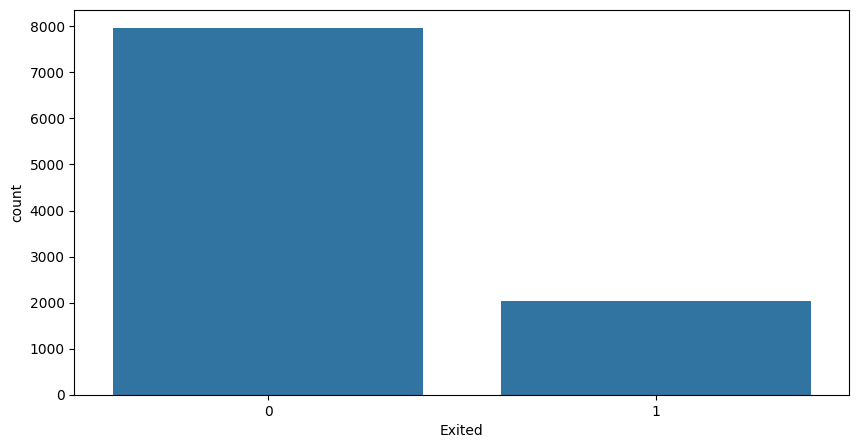

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5))
sns.countplot(x=df['Exited'])
plt.show()

In [27]:
df['Exited'].value_counts()

,count
Exited,
0,7963
1,2037


In [28]:
x=df.drop(['RowNumber','CustomerId','Surname','Exited'],axis=1)
x


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77
9997,709,France,Female,36,7,0.00,1,0,1,42085.58
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52


In [29]:
from sklearn.preprocessing import LabelEncoder
le1=LabelEncoder()
x['Geography']=le1.fit_transform(x['Geography'])
le2=LabelEncoder()
x['Gender']=le2.fit_transform(x['Gender'])
x

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,0,0,42,2,0.00,1,1,1,101348.88
1,608,2,0,41,1,83807.86,1,0,1,112542.58
2,502,0,0,42,8,159660.80,3,1,0,113931.57
3,699,0,0,39,1,0.00,2,0,0,93826.63
4,850,2,0,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9995,771,0,1,39,5,0.00,2,1,0,96270.64
9996,516,0,1,35,10,57369.61,1,1,1,101699.77
9997,709,0,0,36,7,0.00,1,0,1,42085.58
9998,772,1,1,42,3,75075.31,2,1,0,92888.52


In [30]:
x=x.values
x

array([[6.1900000e+02, 0.0000000e+00, 0.0000000e+00, ..., 1.0000000e+00,
        1.0000000e+00, 1.0134888e+05],
       [6.0800000e+02, 2.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        1.0000000e+00, 1.1254258e+05],
       [5.0200000e+02, 0.0000000e+00, 0.0000000e+00, ..., 1.0000000e+00,
        0.0000000e+00, 1.1393157e+05],
       ...,
       [7.0900000e+02, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        1.0000000e+00, 4.2085580e+04],
       [7.7200000e+02, 1.0000000e+00, 1.0000000e+00, ..., 1.0000000e+00,
        0.0000000e+00, 9.2888520e+04],
       [7.9200000e+02, 0.0000000e+00, 0.0000000e+00, ..., 1.0000000e+00,
        0.0000000e+00, 3.8190780e+04]])

In [31]:
y=df['Exited'].values
y

array([1, 0, 1, ..., 1, 1, 0])

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [33]:
print("Total data size=",x.shape)
print("Training data size=",x_train.shape)
print("Testing data size=",x_test.shape)

Total data size= (10000, 10)
Training data size= (8000, 10)
Testing data size= (2000, 10)


In [34]:
model_name=[]
model_accuracy=[]

In [35]:
from keras.models import Sequential
from keras.layers import Dense
ann_model=Sequential()
ann_model.add(Dense(units=128,activation='relu',input_dim=10))  #input layer
ann_model.add(Dense(units=64,activation='relu'))  #hidden layer 1
ann_model.add(Dense(units=32,activation='relu'))  #hidden layer 2
ann_model.add(Dense(units=16,activation='relu'))  #hidden layer 3
ann_model.add(Dense(units=1,activation='sigmoid'))
ann_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
ann_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
ann_model.fit(x_train,y_train,batch_size=32,epochs=100)

Epoch 1/100
171/250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7905 - loss: 0.4987

In [ ]:
y_pred=(ann_model.predict(x_test)>.5).astype(int)
y_pred

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
cm=confusion_matrix(y_test,y_pred)
acc=accuracy_score(y_test,y_pred)
model_name.append("ANN")
model_accuracy.append(acc)
print(cm)
print("Accuracy=",acc)
print(classification_report(y_test,y_pred))

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_model.fit(x_train,y_train)
y_pred=knn_model.predict(x_test)
cm=confusion_matrix(y_test,y_pred)
acc=accuracy_score(y_test,y_pred)
model_name.append("KNN")
model_accuracy.append(acc)
print(cm)
print("Accuracy=",acc)
print(classification_report(y_test,y_pred))


In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=0)
dt_model.fit(x_train,y_train)
y_pred=dt_model.predict(x_test)
cm=confusion_matrix(y_test,y_pred)
acc=accuracy_score(y_test,y_pred)
model_name.append("DT")
model_accuracy.append(acc)
print(cm)
print("Accuracy=",acc)
print(classification_report(y_test,y_pred))

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model=RandomForestClassifier(random_state=0)
rf_model.fit(x_train,y_train)
y_pred=rf_model.predict(x_test)
cm=confusion_matrix(y_test,y_pred)
acc=accuracy_score(y_test,y_pred)
model_name.append("RF")
model_accuracy.append(acc)
print(cm)
print("Accuracy=",acc)
print(classification_report(y_test,y_pred))

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.bar(model_name,model_accuracy)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.grid()
plt.show()